# 🛍️ Mall Shopper Profiling — Unsupervised Learning
**Practical Exam (Set B)** | K-Means • Agglomerative Hierarchical • DBSCAN

**Business problem:** A large Indian mall chain (think Phoenix Marketcity / Nexus Malls) wants to understand how its visitors spend so it can redesign store layouts, plan promotional events and offer personalised loyalty rewards.

**Dataset:** Mall Customer Segmentation Data (Kaggle) — 200 customers, columns: CustomerID, Genre, Age, Annual Income (k$), Spending Score (1-100).

**Goal:** Find natural shopper groups with three clustering algorithms, compare them, and convert them into retail personas and strategies.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
os.makedirs('images', exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig('images/' + name + '.png', dpi=110, bbox_inches='tight')
    plt.show()

# 📂 Step 1: Dataset Loading & EDA
## 1.1 Load & Inspect the Dataset

In [2]:
df = pd.read_csv('Mall_Customers.csv')
print('Shape:', df.shape)
print()
df.info()
df.head(10)

Shape: (200, 5)

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [3]:
df = df.rename(columns={'Genre': 'Gender',
                        'Annual Income (k$)': 'AnnualIncome',
                        'Spending Score (1-100)': 'SpendingScore'})
print(df.columns.tolist())
print()
print('Missing values:')
print(df.isnull().sum())
print()
print('Gender counts:')
print(df['Gender'].value_counts())

['CustomerID', 'Gender', 'Age', 'AnnualIncome', 'SpendingScore']

Missing values:
CustomerID       0
Gender           0
Age              0
AnnualIncome     0
SpendingScore    0
dtype: int64

Gender counts:
Gender
Female    112
Male       88
Name: count, dtype: int64


**Findings:** The dataset has 200 rows and 5 columns. There are **no missing values**, so no imputation is needed. There are **112 female** and **88 male** customers.

## 1.2 Univariate Analysis

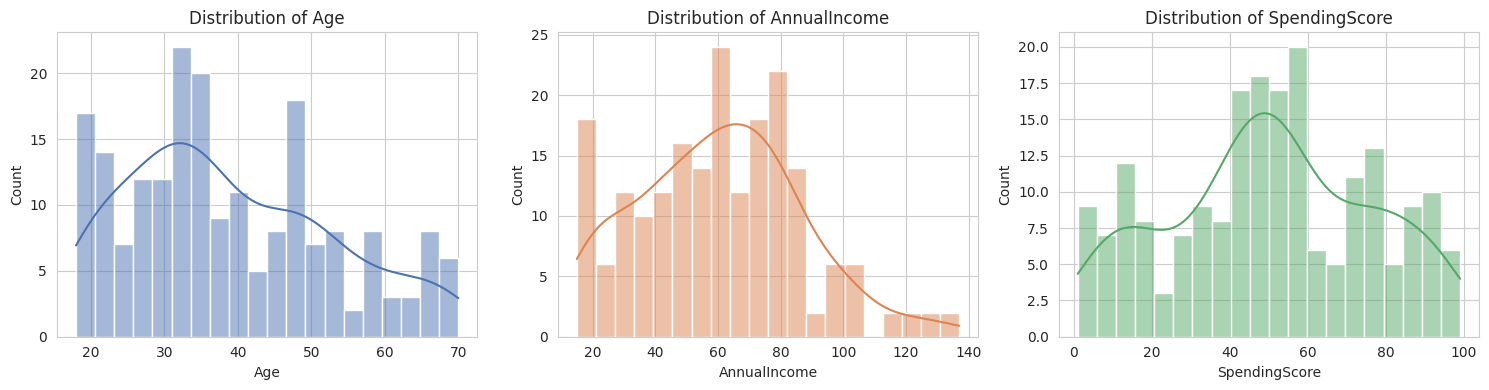

In [4]:
num_cols = ['Age', 'AnnualIncome', 'SpendingScore']
colors = ['#4C72B0', '#DD8452', '#55A868']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, c in zip(axes, num_cols, colors):
    sns.histplot(df[col], bins=20, kde=True, color=c, ax=ax)
    ax.set_title('Distribution of ' + col)
save_fig('01_histograms')

**Distribution comments**
- **Age:** right-skewed (skew ≈ 0.49) – most customers are 25–50, with a smaller tail of seniors up to 70.
- **AnnualIncome:** slightly right-skewed (skew ≈ 0.32), roughly bell-shaped around 60k$ with a thin tail up to 137k$.
- **SpendingScore:** almost symmetric (skew ≈ −0.05) with a wide spread from 1 to 99 – it looks multi-modal, an early hint that there are different shopper types.

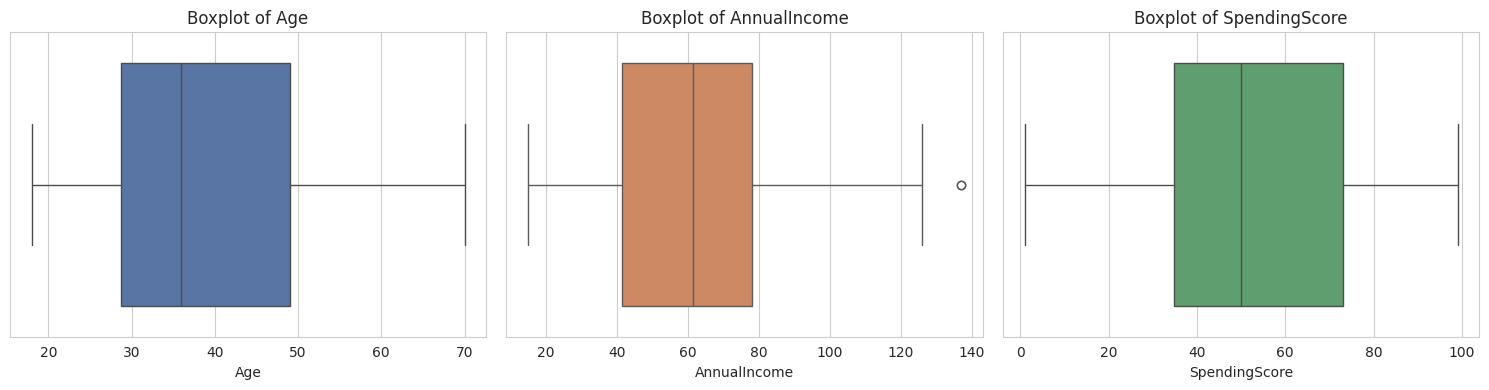

Income outliers (IQR rule): [137, 137]


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, c in zip(axes, num_cols, colors):
    sns.boxplot(x=df[col], color=c, ax=ax)
    ax.set_title('Boxplot of ' + col)
save_fig('02_boxplots')

q1, q3 = df['AnnualIncome'].quantile([0.25, 0.75])
print('Income outliers (IQR rule):', df[df['AnnualIncome'] > q3 + 1.5 * (q3 - q1)]['AnnualIncome'].tolist())

**Outliers:** Only **AnnualIncome** shows visible outliers – two customers at 137k$ sit just beyond the upper whisker. Age and SpendingScore have no outliers. These are genuine high earners, so I keep them.

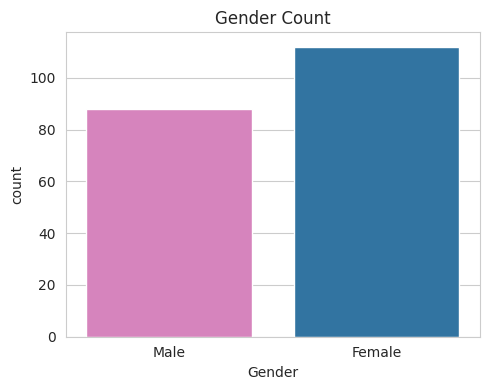

In [6]:
plt.figure(figsize=(5, 4))
sns.countplot(x='Gender', data=df, palette=['#E377C2', '#1F77B4'])
plt.title('Gender Count')
save_fig('03_gender_countplot')

The dataset is **fairly balanced** (56% female vs 44% male) – a slight female majority but not enough to bias clustering.

## 1.3 Bivariate Analysis

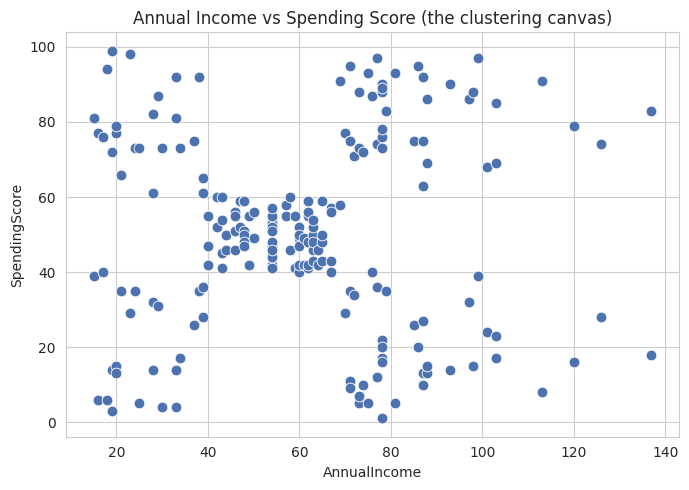

In [7]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x='AnnualIncome', y='SpendingScore', data=df, color='#4C72B0', s=60)
plt.title('Annual Income vs Spending Score (the clustering canvas)')
save_fig('04_income_vs_spending')

### 👀 Can I spot the groups before clustering?
Yes — **five visible groups** appear on the Income vs Spending plot:
1. **Low income, high spending** (top-left)
2. **Low income, low spending** (bottom-left)
3. **Mid income, mid spending** – the big cluster in the centre
4. **High income, high spending** (top-right)
5. **High income, low spending** (bottom-right)

So I expect k = 5 from the algorithms.

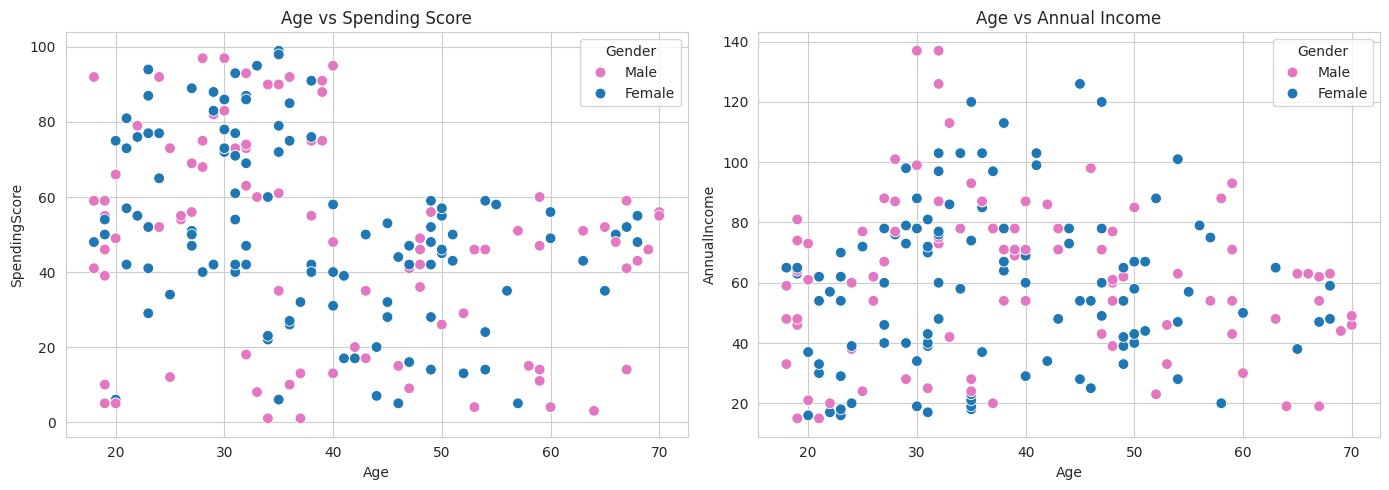

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x='Age', y='SpendingScore', hue='Gender', data=df, palette=['#E377C2', '#1F77B4'], s=60, ax=axes[0])
axes[0].set_title('Age vs Spending Score')
sns.scatterplot(x='Age', y='AnnualIncome', hue='Gender', data=df, palette=['#E377C2', '#1F77B4'], s=60, ax=axes[1])
axes[1].set_title('Age vs Annual Income')
save_fig('05_age_scatters')

- **Age vs SpendingScore:** younger customers (under ~35) reach the highest spending scores; people above 55 rarely score above 60.
- **Age vs AnnualIncome:** no clear pattern – income is spread across all ages. Gender colours are mixed in both plots.

                 Age  AnnualIncome  SpendingScore
Age            1.000        -0.012         -0.327
AnnualIncome  -0.012         1.000          0.010
SpendingScore -0.327         0.010          1.000


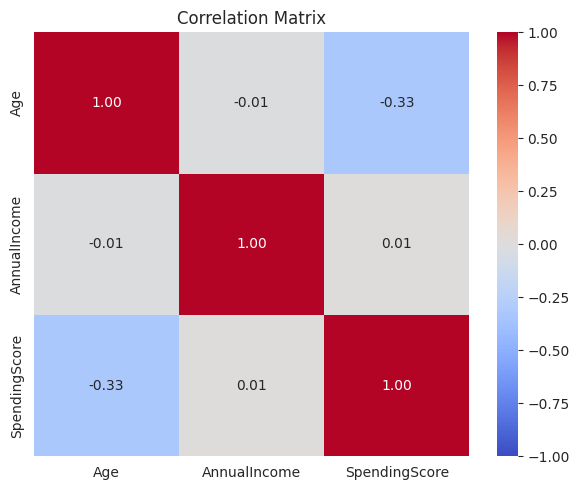

In [9]:
corr = df[['Age', 'AnnualIncome', 'SpendingScore']].corr()
print(corr.round(3))
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
save_fig('06_correlation_heatmap')

Age and SpendingScore have a **weak negative correlation (−0.33)**. Income has almost zero correlation with both Age and SpendingScore (≈ 0), so income alone does not predict spending – that is exactly why clustering on the two together is useful.

## 1.4 Gender-Wise Summary

          Age  AnnualIncome  SpendingScore
Gender                                    
Female  38.10         59.25          51.53
Male    39.81         62.23          48.51


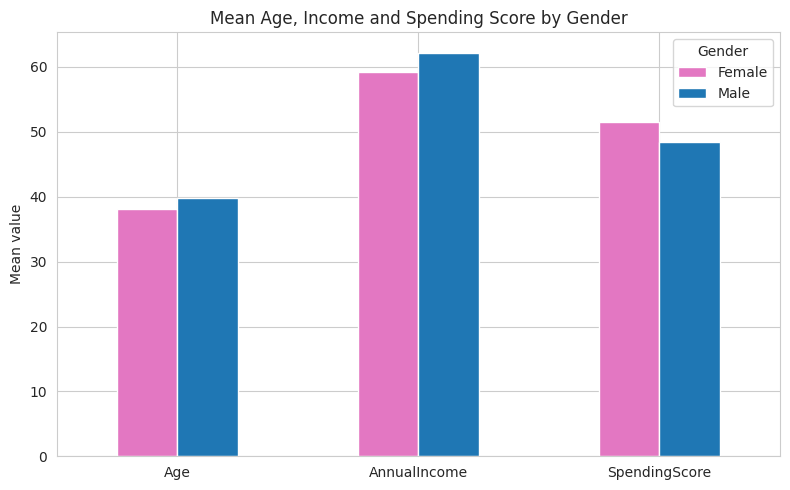

In [10]:
gender_mean = df.groupby('Gender')[num_cols].mean().round(2)
print(gender_mean)
gender_mean.T.plot(kind='bar', figsize=(8, 5), color=['#E377C2', '#1F77B4'])
plt.title('Mean Age, Income and Spending Score by Gender')
plt.ylabel('Mean value')
plt.xticks(rotation=0)
save_fig('07_gender_summary')

Females have a slightly **higher SpendingScore (51.5 vs 48.5)**, while males have slightly higher income (62.2k vs 59.3k) and are marginally older (39.8 vs 38.1). The differences are small, so gender alone is **not** a strong separator of shoppers.

# 🔧 Step 2: Feature Engineering & Preprocessing
## 2.1 Encode Categorical Feature

In [11]:
df['Gender_enc'] = df['Gender'].map({'Female': 0, 'Male': 1})
df[['Gender', 'Gender_enc']].head()

,Gender,Gender_enc
0,Male,1
1,Male,1
2,Female,0
3,Female,0
4,Female,0


## 2.2 Engineer New Features

In [12]:
df['IncomeGroup'] = pd.qcut(df['AnnualIncome'], 3, labels=['Low', 'Medium', 'High'])
df['AgeGroup'] = pd.cut(df['Age'], bins=[17, 25, 40, 55, 100], labels=['Young', 'Adult', 'Middle-Aged', 'Senior'])
df['SpendingCategory'] = pd.cut(df['SpendingScore'], bins=[0, 33, 66, 100], labels=['Low', 'Medium', 'High'])

for c in ['IncomeGroup', 'AgeGroup', 'SpendingCategory']:
    print(df[c].value_counts())
    print()

IncomeGroup
Low       70
High      66
Medium    64
Name: count, dtype: int64

AgeGroup
Adult          84
Middle-Aged    49
Young          38
Senior         29
Name: count, dtype: int64

SpendingCategory
Medium    94
High      57
Low       49
Name: count, dtype: int64



**Are the bins balanced?** `IncomeGroup` is almost perfectly balanced (70 / 64 / 66) because `qcut` makes equal-frequency bins. `AgeGroup` and `SpendingCategory` use fixed ranges, so they are uneven – Adults (84) dominate Age, and Medium (94) dominates Spending. This is fine; these columns are for profiling, not for clustering.

## 2.3 Select Features for Clustering

In [13]:
X_2d = df[['AnnualIncome', 'SpendingScore']]
X_5d = df[['Age', 'AnnualIncome', 'SpendingScore', 'Gender_enc']]
print('X_2d shape:', X_2d.shape)
print('X_5d shape:', X_5d.shape)

X_2d shape: (200, 2)
X_5d shape: (200, 4)


> The exam calls this the "5D" set but it contains **4 features** (Age, AnnualIncome, SpendingScore, Gender_enc) exactly as listed in the task, so I follow the list.

## 2.4 Scale the Features

In [14]:
scaler_2d = StandardScaler()
scaler_5d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)
X_5d_scaled = scaler_5d.fit_transform(X_5d)

print('X_2d_scaled  mean:', X_2d_scaled.mean(axis=0).round(3), ' std:', X_2d_scaled.std(axis=0).round(3))
print('X_5d_scaled  mean:', X_5d_scaled.mean(axis=0).round(3), ' std:', X_5d_scaled.std(axis=0).round(3))

X_2d_scaled  mean: [-0. -0.]  std: [1. 1.]
X_5d_scaled  mean: [-0. -0. -0.  0.]  std: [1. 1. 1. 1.]


Mean ≈ 0 and std = 1 for every feature, so scaling worked. Scaling matters because AnnualIncome (15–137) would otherwise dominate distance calculations over other features.

# 🔵 Step 3: K-Means Clustering
## 3.1 Elbow Method & Silhouette

 k  Inertia (WCSS)  Silhouette
 2          269.69      0.3213
 3          157.70      0.4666
 4          108.92      0.4939
 5           65.57      0.5547
 6           55.06      0.5399
 7           44.86      0.5281
 8           37.23      0.4552
 9           32.39      0.4571
10           29.98      0.4432

Best k by silhouette: 5


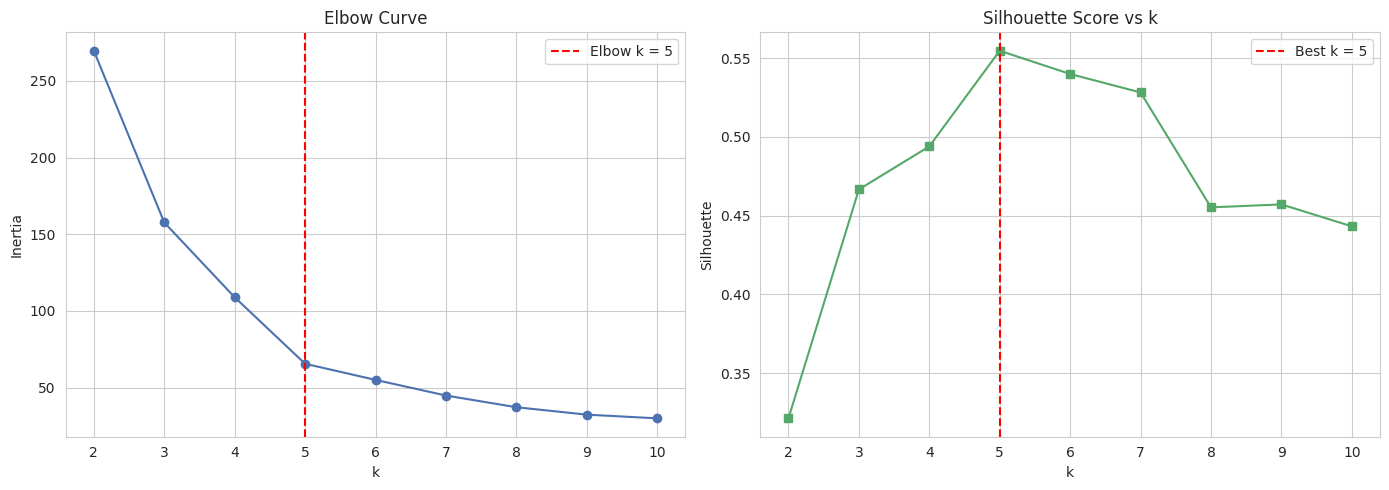

In [15]:
k_range = range(2, 11)
inertias = []
sil_scores = []
for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_2d_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_2d_scaled, km.labels_))

k_table = pd.DataFrame({'k': list(k_range), 'Inertia (WCSS)': np.round(inertias, 2), 'Silhouette': np.round(sil_scores, 4)})
print(k_table.to_string(index=False))

k_optimal = list(k_range)[int(np.argmax(sil_scores))]
print('\nBest k by silhouette:', k_optimal)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(k_range), inertias, 'o-', color='#4C72B0')
axes[0].axvline(k_optimal, color='red', linestyle='--', label='Elbow k = ' + str(k_optimal))
axes[0].set_title('Elbow Curve'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia'); axes[0].legend()
axes[1].plot(list(k_range), sil_scores, 's-', color='#55A868')
axes[1].axvline(k_optimal, color='red', linestyle='--', label='Best k = ' + str(k_optimal))
axes[1].set_title('Silhouette Score vs k'); axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette'); axes[1].legend()
save_fig('08_elbow_silhouette')

**Choice of k = 5.** The inertia curve drops steeply until k = 5 (from 108.9 at k = 4 to 65.6 at k = 5) and then flattens, so the elbow is at 5. The silhouette score also peaks at k = 5 (0.555), which matches the 5 groups I spotted visually in the scatter plot.

## 3.2 Train Final K-Means Model

In [16]:
kmeans_2d = KMeans(n_clusters=k_optimal, init='k-means++', n_init=20, max_iter=500, random_state=42)
df['KMeans_Cluster'] = kmeans_2d.fit_predict(X_2d_scaled)

kmeans_5d = KMeans(n_clusters=k_optimal, init='k-means++', n_init=20, max_iter=500, random_state=42)
df['KMeans_5D_Cluster'] = kmeans_5d.fit_predict(X_5d_scaled)

sil_2d = silhouette_score(X_2d_scaled, df['KMeans_Cluster'])
sil_5d = silhouette_score(X_5d_scaled, df['KMeans_5D_Cluster'])
print('Silhouette 2D (Income + Spending)          :', round(sil_2d, 4))
print('Silhouette 5D (Age + Income + Spend + Gender):', round(sil_5d, 4))

Silhouette 2D (Income + Spending)          : 0.5547
Silhouette 5D (Age + Income + Spend + Gender): 0.3144


The **2D feature set (0.555) gives much better-separated clusters** than the 5D set (0.314). Adding Age and Gender adds dimensions where the groups overlap, which dilutes the clear Income–Spending structure. (Note: the two scores are measured in different spaces, so this is a rough comparison, but the gap is large.)

## 3.3 Visualise K-Means Clusters

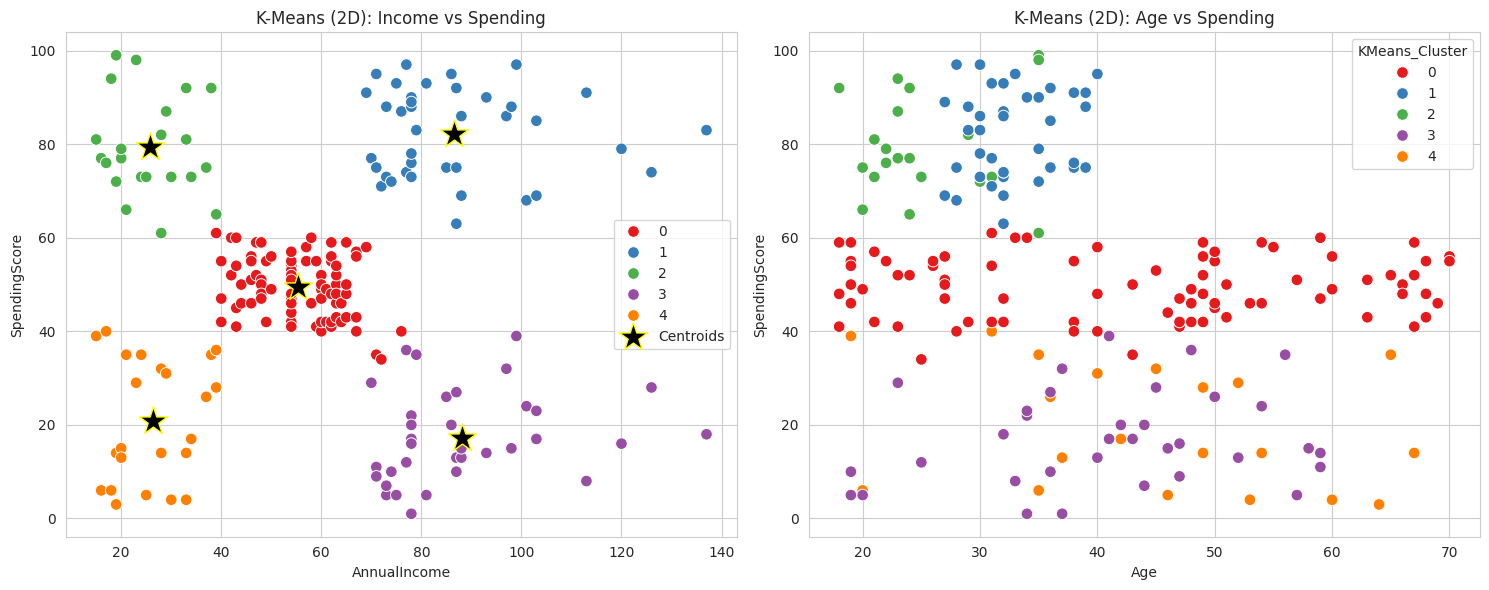

In [17]:
centers = scaler_2d.inverse_transform(kmeans_2d.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x='AnnualIncome', y='SpendingScore', hue='KMeans_Cluster', data=df, palette='Set1', s=70, ax=axes[0])
axes[0].scatter(centers[:, 0], centers[:, 1], marker='*', s=450, c='black', edgecolor='yellow', label='Centroids')
axes[0].set_title('K-Means (2D): Income vs Spending'); axes[0].legend()
sns.scatterplot(x='Age', y='SpendingScore', hue='KMeans_Cluster', data=df, palette='Set1', s=70, ax=axes[1])
axes[1].set_title('K-Means (2D): Age vs Spending')
save_fig('09_kmeans_scatter')

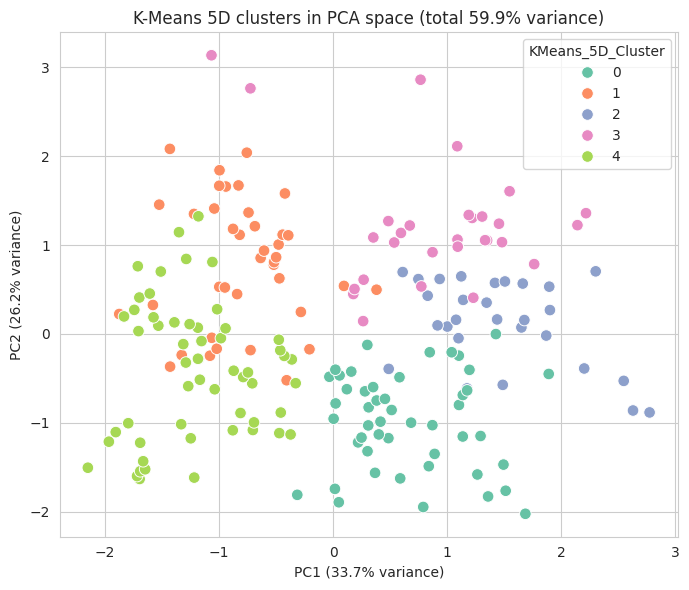

In [18]:
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_5d_scaled)
var = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(7, 6))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df['KMeans_5D_Cluster'], palette='Set2', s=70)
plt.xlabel('PC1 (' + str(round(var[0], 1)) + '% variance)')
plt.ylabel('PC2 (' + str(round(var[1], 1)) + '% variance)')
plt.title('K-Means 5D clusters in PCA space (total ' + str(round(var.sum(), 1)) + '% variance)')
save_fig('10_kmeans_5d_pca')

## 3.4 Profile the K-Means Clusters

In [19]:
def get_persona(income, spend):
    # rule-based persona using the cluster's average (unscaled) income and spending
    if income >= 70 and spend >= 60:
        return 'Big Spenders'
    if income >= 70 and spend < 40:
        return 'Careful Spenders'
    if income < 40 and spend >= 60:
        return 'Young Aspirers'
    if income < 40 and spend < 40:
        return 'Budget Shoppers'
    return 'Mainstream Shoppers'

km_profile = df.groupby('KMeans_Cluster')[num_cols].mean().round(1)
km_profile['Count'] = df['KMeans_Cluster'].value_counts()
km_profile['Persona'] = [get_persona(r['AnnualIncome'], r['SpendingScore']) for _, r in km_profile.iterrows()]
km_profile = km_profile.sort_values('SpendingScore', ascending=False)
print(km_profile)

km_persona_map = km_profile['Persona'].to_dict()
df['KMeans_Persona'] = df['KMeans_Cluster'].map(km_persona_map)

print('\nGender split per cluster (%):')
print((pd.crosstab(df['KMeans_Cluster'], df['Gender'], normalize='index') * 100).round(1))

                 Age  AnnualIncome  SpendingScore  Count              Persona
KMeans_Cluster                                                               
1               32.7          86.5           82.1     39         Big Spenders
2               25.3          25.7           79.4     22       Young Aspirers
0               42.7          55.3           49.5     81  Mainstream Shoppers
4               45.2          26.3           20.9     23      Budget Shoppers
3               41.1          88.2           17.1     35     Careful Spenders

Gender split per cluster (%):
Gender          Female  Male
KMeans_Cluster              
0                 59.3  40.7
1                 53.8  46.2
2                 59.1  40.9
3                 45.7  54.3
4                 60.9  39.1


### Personas (K-Means)
| Persona | Profile | Why this label |
|---|---|---|
| **Big Spenders** | Age ≈ 33, Income ≈ 86.5k, Score ≈ 82 | High income *and* very high spending – the Zara / premium-brand shopper |
| **Young Aspirers** | Age ≈ 25, Income ≈ 26k, Score ≈ 79 | Youngest group, low income but spends a lot – trend-driven and aspirational |
| **Mainstream Shoppers** | Age ≈ 43, Income ≈ 55k, Score ≈ 50 | The largest group (81), average on everything – the Westside shopper |
| **Budget Shoppers** | Age ≈ 45, Income ≈ 26k, Score ≈ 21 | Low income and low spending, oldest group – value / BOGO deal seekers |
| **Careful Spenders** | Age ≈ 41, Income ≈ 88k, Score ≈ 17 | Highest income but lowest spending – wealthy but selective, hard to convert |

# 🌳 Step 4: Agglomerative Hierarchical Clustering
## 4.1 Dendrogram Analysis

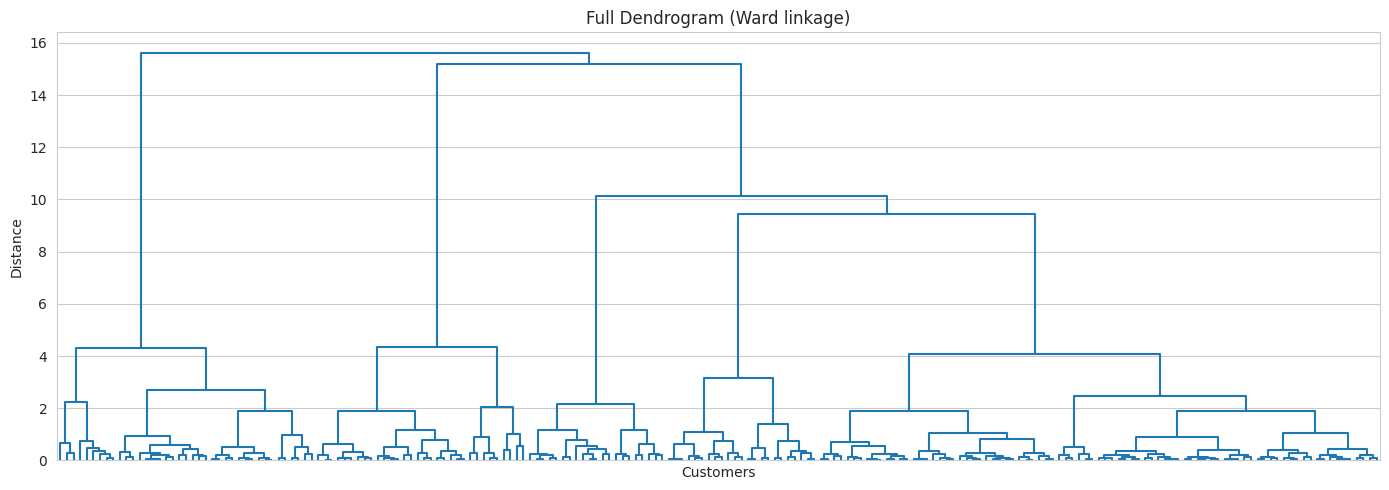

Biggest gap is between distance 4.35 and 9.45
Cut threshold  : 6.9
Clusters at cut: 5


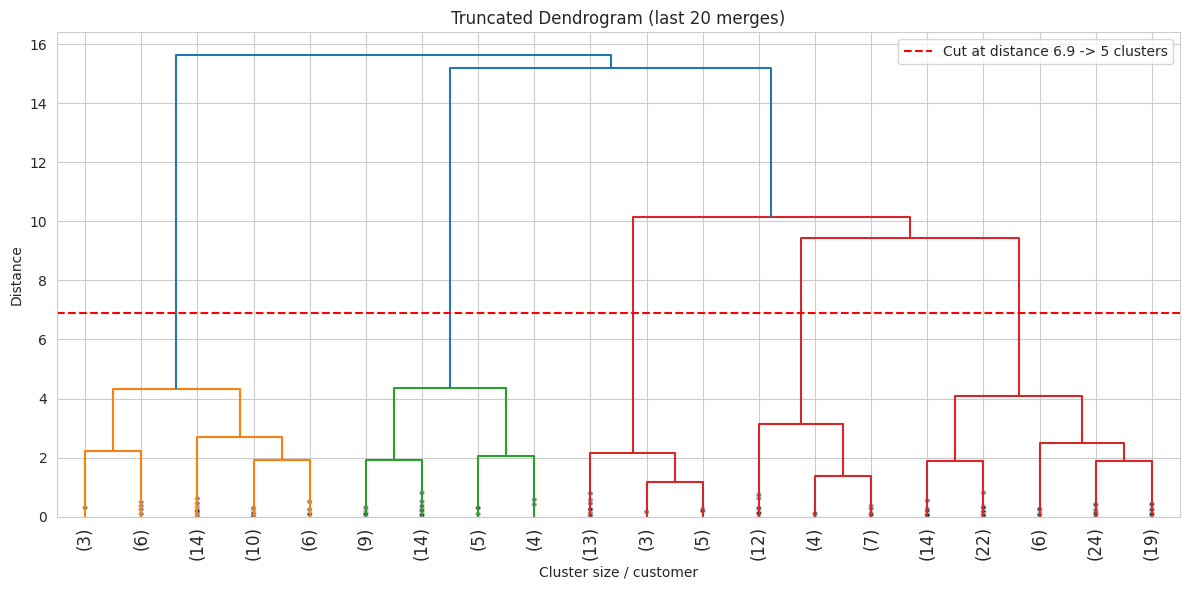

In [20]:
Z = linkage(X_2d_scaled, method='ward')

plt.figure(figsize=(14, 5))
dendrogram(Z, no_labels=True, color_threshold=0)
plt.title('Full Dendrogram (Ward linkage)'); plt.xlabel('Customers'); plt.ylabel('Distance')
save_fig('11_dendrogram_full')

# longest vertical gap between successive merges -> natural cut
heights = Z[:, 2]
gaps = np.diff(heights[-10:])
idx = int(np.argmax(gaps))
lower = heights[-10:][idx]
upper = heights[-10:][idx + 1]
cut = (lower + upper) / 2
n_chosen = int((heights > cut).sum() + 1)
print('Biggest gap is between distance', round(lower, 2), 'and', round(upper, 2))
print('Cut threshold  :', round(cut, 2))
print('Clusters at cut:', n_chosen)

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=20, leaf_rotation=90, show_contracted=True)
plt.axhline(y=cut, color='red', linestyle='--', label='Cut at distance ' + str(round(cut, 2)) + ' -> ' + str(n_chosen) + ' clusters')
plt.title('Truncated Dendrogram (last 20 merges)'); plt.xlabel('Cluster size / customer'); plt.ylabel('Distance'); plt.legend()
save_fig('12_dendrogram_truncated')

**Report:** The largest gap that no horizontal line crosses lies between merge distances ≈ 4.35 and ≈ 9.45. Cutting at **distance ≈ 6.9** gives **5 clusters**, which agrees with K-Means.

## 4.2 Train Agglomerative Model

In [21]:
results = []
agg_models = {}
for link in ['ward', 'complete', 'average']:
    agg = AgglomerativeClustering(n_clusters=n_chosen, linkage=link)
    labels = agg.fit_predict(X_2d_scaled)
    agg_models[link] = labels
    results.append({'Linkage': link, 'Silhouette': round(silhouette_score(X_2d_scaled, labels), 4)})

link_table = pd.DataFrame(results)
print(link_table.to_string(index=False))
best_link = link_table.sort_values('Silhouette', ascending=False).iloc[0]['Linkage']
print('\nBest linkage:', best_link)
df['Agg_Cluster'] = agg_models[best_link]

 Linkage  Silhouette
    ward      0.5538
complete      0.5531
 average      0.4794

Best linkage: ward


**Ward linkage is best** (0.554), narrowly ahead of complete (0.553), while average linkage is clearly weaker (0.479). Ward minimises within-cluster variance, which suits these compact blobs.

## 4.3 Visualise & Profile Hierarchical Clusters

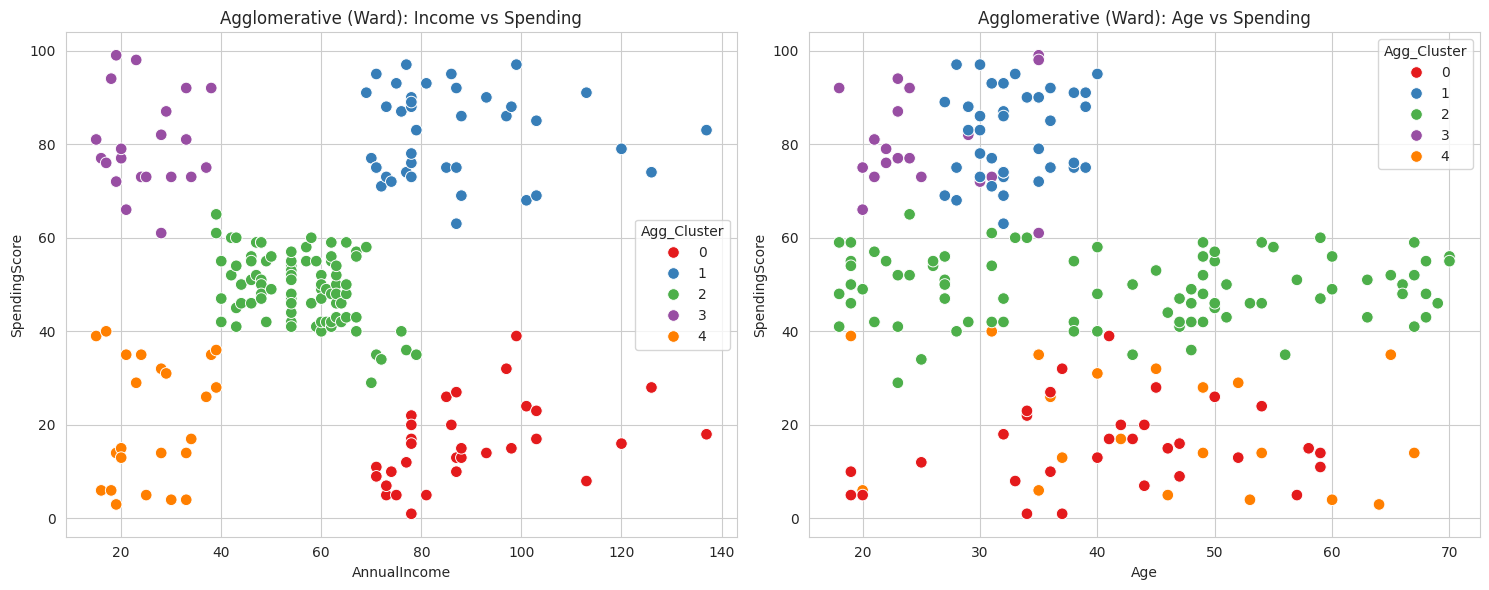

              Age  AnnualIncome  SpendingScore  Count              Persona
Agg_Cluster                                                               
1            32.7          86.5           82.1     39         Big Spenders
3            25.3          25.1           80.0     21       Young Aspirers
2            42.5          55.8           49.1     85  Mainstream Shoppers
4            45.2          26.3           20.9     23      Budget Shoppers
0            41.0          89.4           15.6     32     Careful Spenders


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x='AnnualIncome', y='SpendingScore', hue='Agg_Cluster', data=df, palette='Set1', s=70, ax=axes[0])
axes[0].set_title('Agglomerative (Ward): Income vs Spending')
sns.scatterplot(x='Age', y='SpendingScore', hue='Agg_Cluster', data=df, palette='Set1', s=70, ax=axes[1])
axes[1].set_title('Agglomerative (Ward): Age vs Spending')
save_fig('13_agglomerative_scatter')

agg_profile = df.groupby('Agg_Cluster')[num_cols].mean().round(1)
agg_profile['Count'] = df['Agg_Cluster'].value_counts()
agg_profile['Persona'] = [get_persona(r['AnnualIncome'], r['SpendingScore']) for _, r in agg_profile.iterrows()]
print(agg_profile.sort_values('SpendingScore', ascending=False))
df['Agg_Persona'] = df['Agg_Cluster'].map(agg_profile['Persona'].to_dict())

In [23]:
# cluster numbers are arbitrary, so match them with the Hungarian algorithm before comparing
ct = pd.crosstab(df['KMeans_Cluster'], df['Agg_Cluster'])
print(ct)
r, c = linear_sum_assignment(-ct.values)
same = ct.values[r, c].sum()
agreement = same / len(df) * 100
print('\nCustomers placed in the same cluster by both algorithms:', same, 'of', len(df))
print('Agreement: ' + str(round(agreement, 1)) + '%')

Agg_Cluster      0   1   2   3   4
KMeans_Cluster                    
0                0   0  81   0   0
1                0  39   0   0   0
2                0   0   1  21   0
3               32   0   3   0   0
4                0   0   0   0  23

Customers placed in the same cluster by both algorithms: 196 of 200
Agreement: 98.0%


K-Means and Ward hierarchical clustering look almost identical visually and agree on **98% of customers** (196 of 200). This is even higher than the 80–90% suggested in the exam note, because the Income–Spending clusters are very well separated; only a few boundary customers differ.

# 🔴 Step 5: DBSCAN Clustering
## 5.1 Tune Epsilon with k-NN Distance Plot

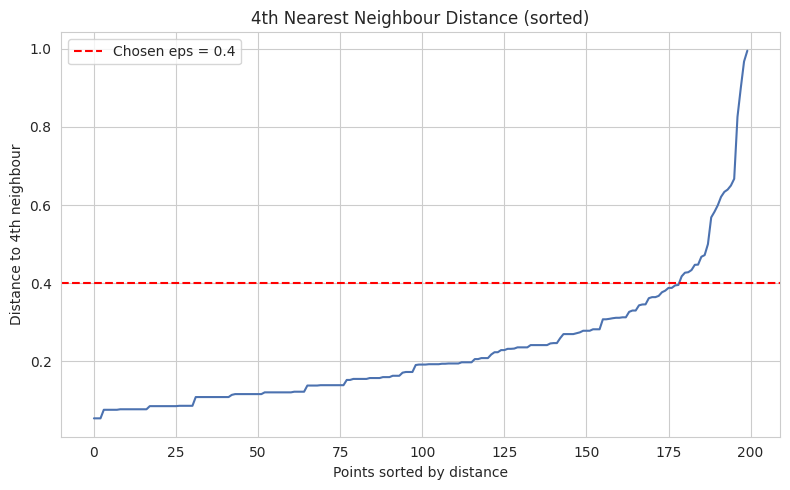

Distance at 90th percentile: 0.419 | at 95th percentile: 0.584


In [24]:
nn = NearestNeighbors(n_neighbors=4).fit(X_2d_scaled)
distances, _ = nn.kneighbors(X_2d_scaled)
kdist = np.sort(distances[:, 3])

optimal_eps = 0.4
plt.figure(figsize=(8, 5))
plt.plot(kdist, color='#4C72B0')
plt.axhline(optimal_eps, color='red', linestyle='--', label='Chosen eps = ' + str(optimal_eps))
plt.title('4th Nearest Neighbour Distance (sorted)'); plt.xlabel('Points sorted by distance'); plt.ylabel('Distance to 4th neighbour'); plt.legend()
save_fig('14_knn_distance')
print('Distance at 90th percentile:', round(np.percentile(kdist, 90), 3), '| at 95th percentile:', round(np.percentile(kdist, 95), 3))

**Chosen ε = 0.4.** The curve stays flat (below ≈ 0.35) for about 85% of the points and then bends sharply upward, so ε ≈ 0.4 sits right at the elbow – small enough to keep clusters tight but large enough that dense-region points are not flagged as noise.

## 5.2 Train DBSCAN Model

In [25]:
db = DBSCAN(eps=optimal_eps, min_samples=4, metric='euclidean')
df['DBSCAN_Cluster'] = db.fit_predict(X_2d_scaled)

n_clusters = len(set(df['DBSCAN_Cluster'])) - (1 if -1 in df['DBSCAN_Cluster'].values else 0)
n_noise = (df['DBSCAN_Cluster'] == -1).sum()
print('(a) Clusters found (excluding noise):', n_clusters)
print('(b) Noise points:', n_noise, '(' + str(round(n_noise / len(df) * 100, 1)) + '%)')

(a) Clusters found (excluding noise): 3
(b) Noise points: 14 (7.0%)


## 5.3 Tune DBSCAN Hyperparameters

 eps  min_samples  clusters  noise %  silhouette
 0.2            3        13     22.0      0.4697
 0.4            3         4      5.0      0.3954
 0.4            4         3      7.0      0.4576
 0.4            5         4      7.5      0.4781
 0.4            7         4     10.0      0.4946
 0.4           10         4     25.5      0.5972


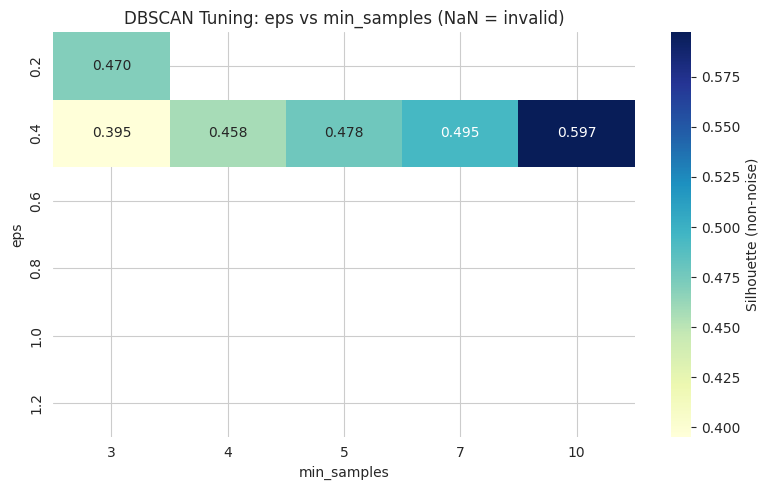


Best parameters -> eps: 0.4 , min_samples: 10 , silhouette: 0.5972


In [26]:
eps_list = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]
min_list = [3, 4, 5, 7, 10]
grid = pd.DataFrame(np.nan, index=eps_list, columns=min_list)
info = []

for e in eps_list:
    for m in min_list:
        lab = DBSCAN(eps=e, min_samples=m).fit_predict(X_2d_scaled)
        ncl = len(set(lab)) - (1 if -1 in lab else 0)
        noise_pct = (lab == -1).mean()
        if ncl >= 2 and noise_pct < 0.30:
            mask = lab != -1
            grid.loc[e, m] = silhouette_score(X_2d_scaled[mask], lab[mask])
            info.append((e, m, ncl, round(noise_pct * 100, 1), round(grid.loc[e, m], 4)))

print(pd.DataFrame(info, columns=['eps', 'min_samples', 'clusters', 'noise %', 'silhouette']).to_string(index=False))

plt.figure(figsize=(8, 5))
sns.heatmap(grid.astype(float), annot=True, fmt='.3f', cmap='YlGnBu', cbar_kws={'label': 'Silhouette (non-noise)'})
plt.title('DBSCAN Tuning: eps vs min_samples (NaN = invalid)'); plt.xlabel('min_samples'); plt.ylabel('eps')
save_fig('15_dbscan_grid_heatmap')

best_eps, best_min = grid.stack().idxmax()
print('\nBest parameters -> eps:', best_eps, ', min_samples:', best_min, ', silhouette:', round(grid.stack().max(), 4))

In [27]:
db_best = DBSCAN(eps=best_eps, min_samples=int(best_min))
df['DBSCAN_Cluster'] = db_best.fit_predict(X_2d_scaled)
n_clusters = len(set(df['DBSCAN_Cluster'])) - (1 if -1 in df['DBSCAN_Cluster'].values else 0)
n_noise = (df['DBSCAN_Cluster'] == -1).sum()
print('Final DBSCAN -> clusters:', n_clusters, '| noise:', n_noise, '(' + str(round(n_noise / len(df) * 100, 1)) + '%)')
print(df['DBSCAN_Cluster'].value_counts().sort_index())

Final DBSCAN -> clusters: 4 | noise: 51 (25.5%)
DBSCAN_Cluster
-1    51
 0    11
 1    87
 2    29
 3    22
Name: count, dtype: int64


Only the combinations with eps = 0.2 and 0.4 give valid results – for eps ≥ 0.6 DBSCAN merges everything into **one** big cluster. The best setting is **eps = 0.4, min_samples = 10** (silhouette 0.597). Its trade-off: it flags ~25% of customers as noise, close to the 30% limit.

## 5.4 Visualise & Profile DBSCAN Clusters

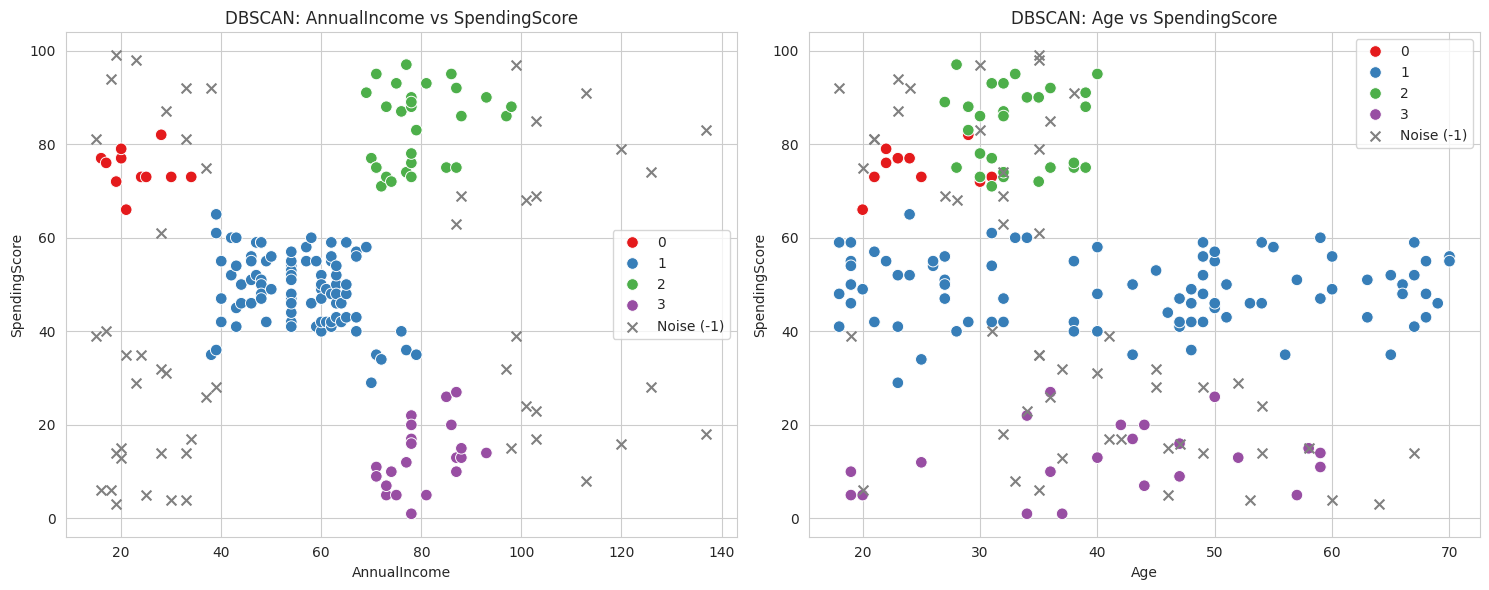

                 Age  AnnualIncome  SpendingScore  Count              Persona
DBSCAN_Cluster                                                               
0               25.2          23.1           74.6     11       Young Aspirers
1               42.8          55.4           48.8     87  Mainstream Shoppers
2               32.9          79.2           83.6     29         Big Spenders
3               41.0          80.2           12.7     22     Careful Spenders

Noise points mean profile:
Age              37.5
AnnualIncome     58.3
SpendingScore    44.5
dtype: float64


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, xcol in zip(axes, ['AnnualIncome', 'Age']):
    noise = df[df['DBSCAN_Cluster'] == -1]
    core = df[df['DBSCAN_Cluster'] != -1]
    sns.scatterplot(x=xcol, y='SpendingScore', hue='DBSCAN_Cluster', data=core, palette='Set1', s=70, ax=ax)
    ax.scatter(noise[xcol], noise['SpendingScore'], c='grey', marker='x', s=50, label='Noise (-1)')
    ax.set_title('DBSCAN: ' + xcol + ' vs SpendingScore'); ax.legend()
save_fig('16_dbscan_scatter')

db_profile = df[df['DBSCAN_Cluster'] != -1].groupby('DBSCAN_Cluster')[num_cols].mean().round(1)
db_profile['Count'] = df[df['DBSCAN_Cluster'] != -1]['DBSCAN_Cluster'].value_counts()
db_profile['Persona'] = [get_persona(r['AnnualIncome'], r['SpendingScore']) for _, r in db_profile.iterrows()]
print(db_profile)

print('\nNoise points mean profile:')
print(df[df['DBSCAN_Cluster'] == -1][num_cols].mean().round(1))

### DBSCAN personas
DBSCAN finds **4 dense clusters**: Young Aspirers (low income, high spending), Mainstream Shoppers (the dense centre), Big Spenders and Careful Spenders. It **does not form a separate Budget Shoppers cluster** – most of that sparser group is labelled noise.

### Who are the noise shoppers?
The 51 noise customers have an average profile of Age ≈ 37.5, Income ≈ 58k, Score ≈ 44.5 – close to the *dataset average*, but this is only because the group is a **mix from opposite corners** of the plot, and the averages cancel out. Cross-checking against K-Means shows 21 of the 51 are **Budget Shoppers** (21 of that group's 23 customers), plus about 10 each from Big Spenders, Careful Spenders and Young Aspirers. Not one Mainstream Shopper is noise.

So the noise shoppers are **not "average" customers and not extreme outliers**: they are the sparser fringe of the small segments, and the whole low-income / low-spending group, whose density falls below min_samples = 10. They are real customers and still need a strategy (see Step 6.3).

# 📊 Step 6: Algorithm Comparison & Business Interpretation
## 6.1 Internal Metrics Comparison

In [29]:
def metrics(X, labels):
    mask = labels != -1          # DBSCAN: score only non-noise points
    return (silhouette_score(X[mask], labels[mask]),
            davies_bouldin_score(X[mask], labels[mask]),
            calinski_harabasz_score(X[mask], labels[mask]))

rows = []
for name, params, col in [
    ('K-Means', 'k=5, k-means++, n_init=20', 'KMeans_Cluster'),
    ('Agglomerative', 'n_clusters=5, linkage=' + best_link, 'Agg_Cluster'),
    ('DBSCAN', 'eps=' + str(best_eps) + ', min_samples=' + str(int(best_min)), 'DBSCAN_Cluster')]:
    lab = df[col].values
    s, d, c = metrics(X_2d_scaled, lab)
    rows.append({'Algorithm': name, 'Hyperparameters': params,
                 'Clusters': len(set(lab)) - (1 if -1 in lab else 0),
                 'Silhouette (higher better)': round(s, 4),
                 'Davies-Bouldin (lower better)': round(d, 4),
                 'Calinski-Harabasz (higher better)': round(c, 2),
                 'Noise %': round((lab == -1).mean() * 100, 1)})

comparison = pd.DataFrame(rows).set_index('Algorithm')
display(comparison)

rank = pd.DataFrame({
    'Silhouette': comparison['Silhouette (higher better)'].rank(ascending=False),
    'Davies-Bouldin': comparison['Davies-Bouldin (lower better)'].rank(ascending=True),
    'Calinski-Harabasz': comparison['Calinski-Harabasz (higher better)'].rank(ascending=False)})
rank['Average Rank'] = rank.mean(axis=1)
print('Ranking (1 = best):')
print(rank.sort_values('Average Rank'))

,Hyperparameters,Clusters,Silhouette (higher better),Davies-Bouldin (lower better),Calinski-Harabasz (higher better),Noise %
Algorithm,,,,,,
K-Means,"k=5, k-means++, n_init=20",5,0.5547,0.5722,248.65,0.0
Agglomerative,"n_clusters=5, linkage=ward",5,0.5538,0.5779,244.41,0.0
DBSCAN,"eps=0.4, min_samples=10",4,0.5972,0.4734,263.61,25.5


Ranking (1 = best):
               Silhouette  Davies-Bouldin  Calinski-Harabasz  Average Rank
Algorithm                                                                 
DBSCAN                1.0             1.0                1.0           1.0
K-Means               2.0             2.0                2.0           2.0
Agglomerative         3.0             3.0                3.0           3.0


**Ranking & conclusion:** *(see the table above)* DBSCAN scores highest on raw metrics, but only because its metrics are computed on the 74.5% of customers that are *not* noise – it has simply removed the hard-to-cluster points. **K-Means and Agglomerative** cover **100%** of customers with almost the same scores. Among the algorithms that assign every shopper, **K-Means is the best / most compact** (highest Calinski-Harabasz and Silhouette by a tiny margin over Ward), so it is my final choice.

## 6.2 Cluster Stability Check for K-Means

In [30]:
seeds = [0, 7, 21, 42, 99]
stab = []
for s in seeds:
    km = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=s).fit(X_2d_scaled)
    stab.append(silhouette_score(X_2d_scaled, km.labels_))
    print('random_state =', s, '-> silhouette =', round(stab[-1], 4))
print('\nMean +/- Std:', round(np.mean(stab), 4), '+/-', round(np.std(stab), 6))

random_state = 0 -> silhouette = 0.5547
random_state = 7 -> silhouette = 0.5547
random_state = 21 -> silhouette = 0.5547
random_state = 42 -> silhouette = 0.5547
random_state = 99 -> silhouette = 0.5547

Mean +/- Std: 0.5547 +/- 0.0


K-Means is **very stable** here: the silhouette is identical across all 5 seeds (std ≈ 0). The dataset is small, clean and has five well-separated blobs, and `k-means++` with multiple initialisations finds the same solution every time.

## 6.3 Business Recommendation

### 📝 Business Recommendation

**To:** Retail Operations Director, Nexus Malls / Phoenix Marketcity
**From:** Junior Data Scientist, Retail Analytics
**Subject:** Shopper segmentation – recommended approach and actions

**1. Recommended algorithm: K-Means (k = 5) on Annual Income + Spending Score.**
K-Means gives a Silhouette Score of **0.555**, Davies-Bouldin of **0.572** and Calinski-Harabasz of **248.7**, with **0% noise** – every shopper is assigned to a segment. Ward hierarchical clustering is almost identical (0.554 / 0.578 / 244.4) and agrees with K-Means for **98%** of customers, which confirms the segments are real. DBSCAN has higher raw scores (0.597 / 0.473 / 263.6), but only after leaving out **25.5%** of shoppers as noise, and it cannot score new customers directly. K-Means is also perfectly stable across random seeds (std ≈ 0) and works in the live `classify_shopper()` function.

**2. Customer segments**

| Segment | Size | One-line description |
|---|---|---|
| **Big Spenders** | 39 | High income (~86k) and high spending (~82); age ~33 – premium-brand buyers |
| **Young Aspirers** | 22 | Low income (~26k) but high spending (~79); youngest group (~25) – trend and fashion driven |
| **Mainstream Shoppers** | 81 | Average income (~55k) and spending (~50); the largest group – everyday family shoppers |
| **Budget Shoppers** | 23 | Low income (~26k) and low spending (~21); oldest group (~45) – value / deal seekers |
| **Careful Spenders** | 35 | High income (~88k) but low spending (~17) – wealthy but not yet engaged with the mall |

**3. One concrete strategy per segment**
- **Big Spenders →** Open a premium lounge with curated luxury-brand pop-ups near the food court, and give early access to seasonal sales through a loyalty tier.
- **Young Aspirers →** Run social-media-driven events (fashion drops, student nights, gaming zones) and offer instalment / BNPL-style offers and app cashback.
- **Mainstream Shoppers →** Use family-oriented bundles (weekend combo offers, kids' activity zone, points on every bill) to raise visit frequency, as this is the largest revenue base.
- **Budget Shoppers →** Place value-for-money stores near the mall entrances and send ₹50-off coupons and BOGO alerts through the mall app.
- **Careful Spenders →** Target with personalised high-value experiences (premium dining, home and electronics expos, concierge service) to convert their high income into spending.

**4. Additional data that would improve segmentation**
Purchase category and basket value data, visit frequency and dwell time from footfall sensors, loyalty-app behaviour and coupon redemption, and the shopper's city / pin code. These would let us move from "how much" to "what and when" people buy.

# 🚀 Step 7: Pipeline & Deployment
## 7.1 Save the Final Pipeline

In [31]:
best_model = kmeans_2d          # final K-Means (k=5) trained on scaled Income + Spending
scaler = scaler_2d              # StandardScaler fitted on Income + Spending

joblib.dump(scaler, 'mall_scaler.pkl')
joblib.dump(best_model, 'mall_segmentation_model.pkl')
print('Saved: mall_scaler.pkl and mall_segmentation_model.pkl')

Saved: mall_scaler.pkl and mall_segmentation_model.pkl


In [32]:
def classify_shopper(age, annual_income, spending_score, gender=None):
    # the final model uses AnnualIncome + SpendingScore; age and gender are accepted for the API but not used
    sc = joblib.load('mall_scaler.pkl')
    model = joblib.load('mall_segmentation_model.pkl')
    new = pd.DataFrame([[annual_income, spending_score]], columns=['AnnualIncome', 'SpendingScore'])
    cluster = int(model.predict(sc.transform(new))[0])
    return cluster, km_persona_map[cluster]

tests = [
    (22, 'Female', 30, 85),
    (35, 'Male', 95, 90),
    (48, 'Female', 90, 15),
    (55, 'Male', 20, 12),
    (40, 'Female', 55, 50)]

out = []
for age, gender, inc, sc in tests:
    cl, persona = classify_shopper(age, inc, sc, gender)
    out.append({'Age': age, 'Gender': gender, 'AnnualIncome (k)': inc, 'SpendingScore': sc, 'Cluster': cl, 'Persona': persona})
pd.DataFrame(out)

,Age,Gender,AnnualIncome (k),SpendingScore,Cluster,Persona
0,22,Female,30,85,2,Young Aspirers
1,35,Male,95,90,1,Big Spenders
2,48,Female,90,15,3,Careful Spenders
3,55,Male,20,12,4,Budget Shoppers
4,40,Female,55,50,0,Mainstream Shoppers


The function works on all 5 hypothetical shoppers, e.g. the 22-year-old female with income 30 and score 85 is correctly tagged as a **Young Aspirer**. (Income is in the same units as the dataset, i.e. thousands.)

In [33]:
df.to_csv('Mall_Customers_clustered.csv', index=False)
print('Done. All outputs generated.')

Done. All outputs generated.


---
## ✅ Summary
All 7 steps completed: EDA → feature engineering → K-Means (2D & 4-feature) → Agglomerative → DBSCAN with tuning → metric comparison → business strategy → saved pipeline.